In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings("ignore")

In [13]:
print("Files in Colab:")
print(os.listdir("/content"))

Files in Colab:
['.config', 'drive', 'DataCoSupplyChainDataset.csv', 'sample_data']


In [14]:
df = pd.read_csv(
      "/content/DataCoSupplyChainDataset.csv",
          encoding="latin1")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [15]:
df_uncleaned = df.copy()

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer 

In [19]:
missing = df.isnull().sum()

missing = missing[missing > 0]

print("Columns with missing values:")
print(missing)

Columns with missing values:
Customer Lname              8
Customer Zipcode            3
Order Zipcode          155679
Product Description    180519
dtype: int64


In [20]:
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns

for col in numeric_columns:
    if df[col].isnull().sum() > 0:
            df[col] = df[col].fillna(df[col].median())

print("Missing numerical values filled.")

Missing numerical values filled.


In [21]:
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())

print("\nDataset shape:", df.shape)


Total missing values: 180527
Total duplicate rows: 0

Dataset shape: (180519, 53)


In [23]:
text_columns = df.select_dtypes(include=["object", "string"]).columns

for col in text_columns:
    df[col] = df[col].apply(
            lambda x: x.strip() if isinstance(x, str) else x
                )

print("Text columns cleaned successfully!")

Text columns cleaned successfully!


In [24]:
df.to_csv("Cleaned_Supply_Chain_Dataset.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [27]:
binary_columns = df.columns[21:]

for col in binary_columns:
    print(col, df[col].unique())

Department Name ['Fitness' 'Apparel' 'Golf' 'Footwear' 'Outdoors' 'Fan Shop' 'Technology'
 'Book Shop' 'Discs Shop' 'Pet Shop' 'Health and Beauty']
Latitude [18.2514534  18.27945137 37.29223251 ... 18.24048233 18.26129723
 18.24248505]
Longitude [ -66.03705597  -66.0370636  -121.881279   ... -117.8856812   -87.69457245
  -66.54897308]
Market ['Pacific Asia' 'USCA' 'Africa' 'Europe' 'LATAM']
Order City ['Bekasi' 'Bikaner' 'Townsville' ... 'Tongling' 'Liuyang' 'Nashua']
Order Country ['Indonesia' 'India' 'Australia' 'China' 'Japón' 'Corea del Sur'
 'Singapur' 'Turquía' 'Mongolia' 'Estados Unidos' 'Nigeria'
 'República Democrática del Congo' 'Senegal' 'Marruecos' 'Alemania'
 'Francia' 'Países Bajos' 'Reino Unido' 'Guatemala' 'El Salvador' 'Panamá'
 'República Dominicana' 'Venezuela' 'Colombia' 'Honduras' 'Brasil'
 'México' 'Uruguay' 'Argentina' 'Cuba' 'Perú' 'Nicaragua' 'Ecuador'
 'Angola' 'Sudán' 'Somalia' 'Costa de Marfil' 'Egipto' 'Italia' 'España'
 'Suecia' 'Austria' 'Canada' 'Madagas

In [28]:
for col in df.columns:
    if df[col].nunique(dropna=False) <= 1:
            print(col, "has no variation")

Customer Email has no variation
Customer Password has no variation
Product Description has no variation
Product Status has no variation


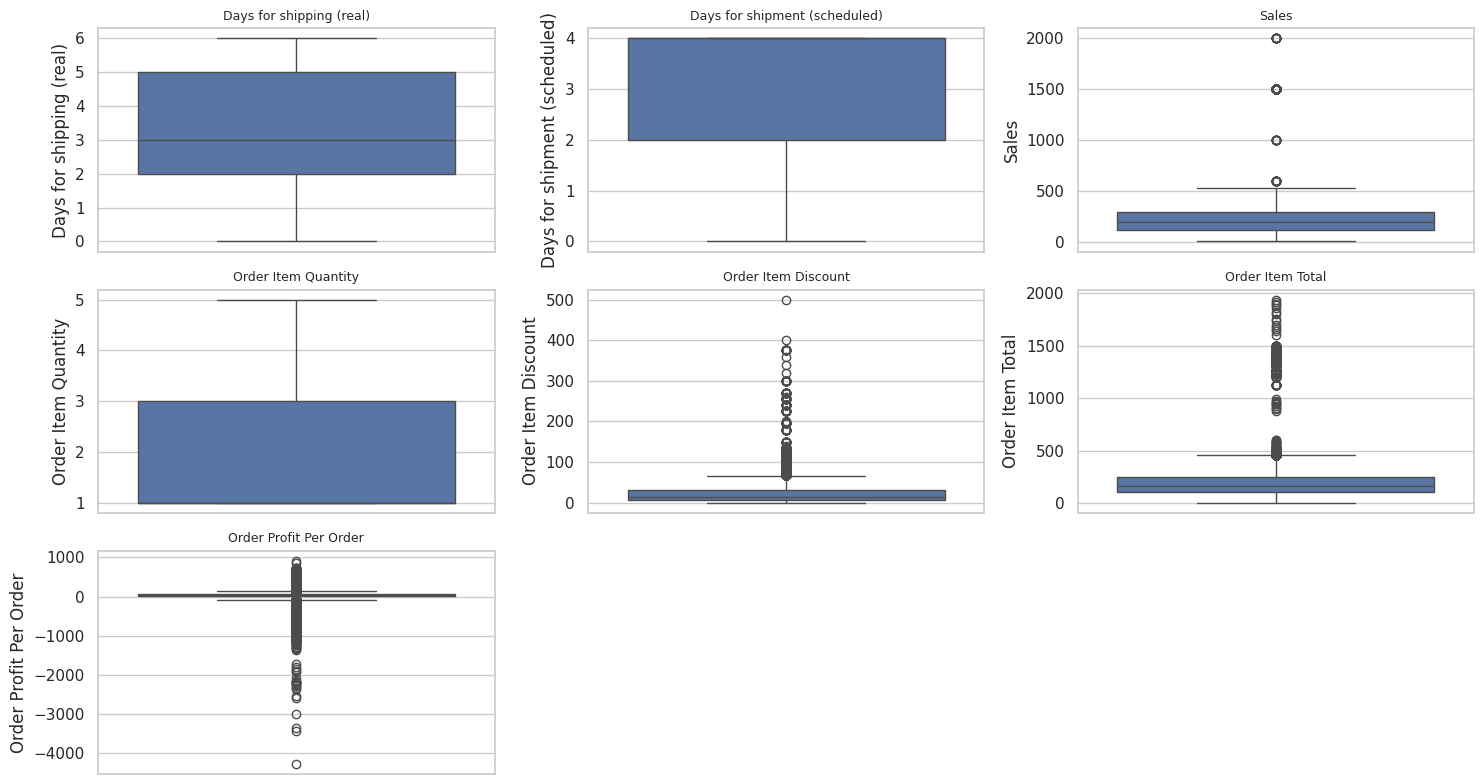

In [30]:
outlier_columns = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Sales",
    "Order Item Quantity",
    "Order Item Discount",
    "Order Item Total",
    "Order Profit Per Order"
]

outlier_columns = [
    col for col in outlier_columns
    if col in df_uncleaned.columns
    and pd.api.types.is_numeric_dtype(df_uncleaned[col])
]
plt.figure(figsize=(15, 8))

for i, col in enumerate(outlier_columns, 1):
  plt.subplot(3, 3, i)
  sns.boxplot(y=df_uncleaned[col])
  plt.title(col, fontsize=9)

plt.tight_layout()
plt.show()

In [31]:
print("IQR Outliers in Uncleaned Data")

for col in outlier_columns:
    Q1 = df_uncleaned[col].quantile(0.25)
    Q3 = df_uncleaned[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = (
        (df_uncleaned[col] < lower_limit) |
        (df_uncleaned[col] > upper_limit)
    ).sum()

print(col, ":", int(outliers))

IQR Outliers in Uncleaned Data
Order Profit Per Order : 18942


In [32]:
print("Z-Score Outliers in Uncleaned Data")

for col in outlier_columns:
  values = df_uncleaned[col].dropna()
  std = values.std()

  if std > 0:
    z_scores = (
      (values - values.mean()) / std
    ).abs()

    outliers = (z_scores > 3).sum()
  else:
    outliers = 0

print(col, ":", int(outliers))

Z-Score Outliers in Uncleaned Data
Order Profit Per Order : 3608


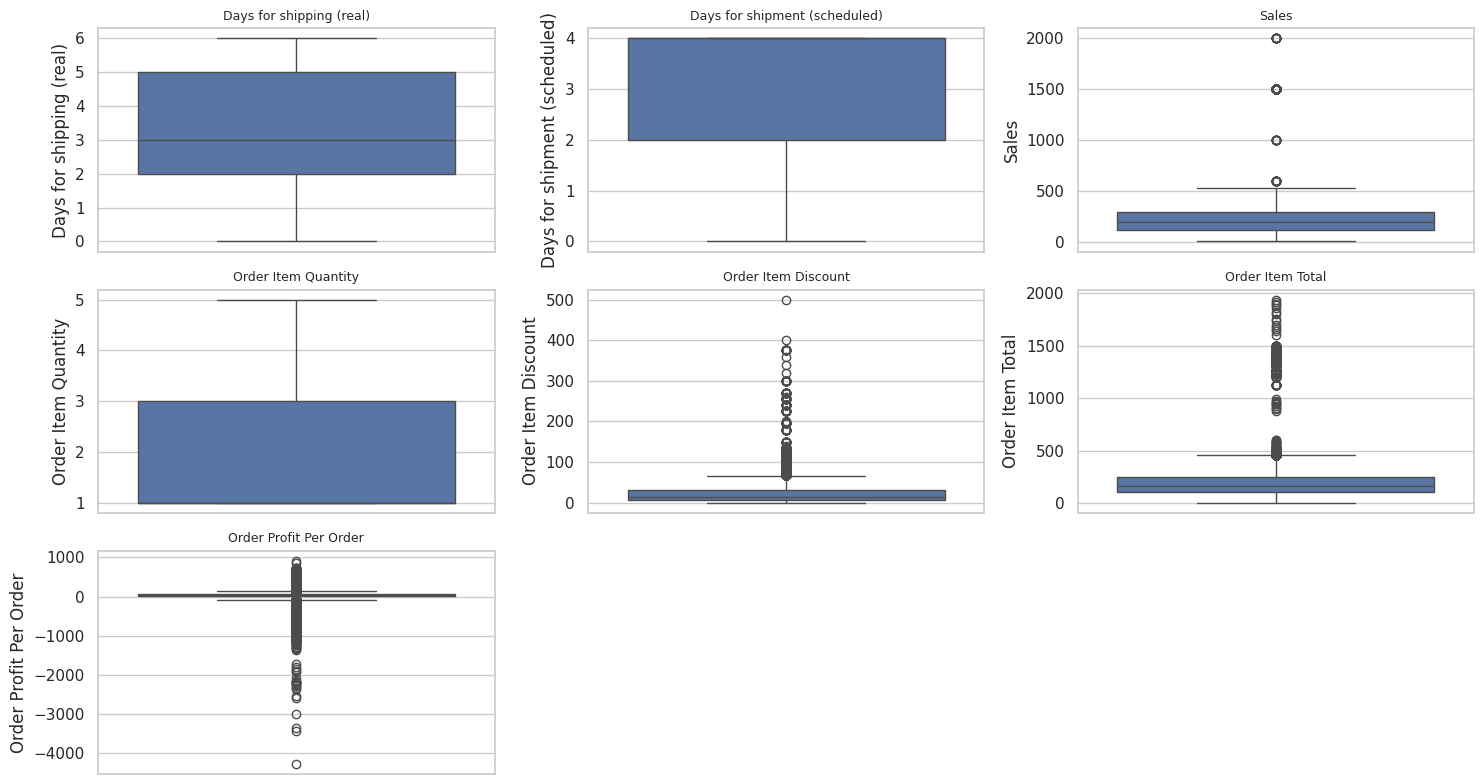

In [33]:
plt.figure(figsize=(15, 8))

for i, col in enumerate(outlier_columns, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col, fontsize=9)

plt.tight_layout()
plt.show()

In [34]:
print("IQR Outliers in Cleaned Data")

for col in outlier_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = (
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ).sum()
print(col, ":", int(outliers))

IQR Outliers in Cleaned Data
Order Profit Per Order : 18942


In [35]:
print("Z-Score Outliers in Cleaned Data")

for col in outlier_columns:
    values = df[col].dropna()
    std = values.std()

    if std > 0:
        z_scores = (
            (values - values.mean()) / std
        ).abs()

        outliers = (z_scores > 3).sum()
    else:
        outliers = 0

print(col, ":", int(outliers))

Z-Score Outliers in Cleaned Data
Order Profit Per Order : 3608


In [36]:
comparison = []

for col in outlier_columns:
    row = {"Column": col}

    for stage, data in [
        ("Before Cleaning", df_uncleaned),
        ("After Cleaning", df)
    ]:
        values = data[col].dropna()

        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1

        iqr_count = (
            (values < Q1 - 1.5 * IQR) |
            (values > Q3 + 1.5 * IQR)
        ).sum()

        std = values.std()

        if std > 0:
            z_count = (
                ((values - values.mean()) / std).abs() > 3
            ).sum()
        else:
            z_count = 0

        row[stage + " IQR"] = int(iqr_count)
        row[stage + " Z-Score"] = int(z_count)

    comparison.append(row)
comparison_df = pd.DataFrame(comparison)
display(comparison_df)

,Column,Before Cleaning IQR,Before Cleaning Z-Score,After Cleaning IQR,After Cleaning Z-Score
0,Days for shipping (real),0,0,0,0
1,Days for shipment (scheduled),0,0,0,0
2,Sales,488,467,488,467
3,Order Item Quantity,0,0,0,0
4,Order Item Discount,7537,2106,7537,2106
5,Order Item Total,1943,477,1943,477
6,Order Profit Per Order,18942,3608,18942,3608
